# Systemy AI – Laboratorium 1
## Python, NumPy i pierwsze metryki klasyfikacji

**Cel:** przypomnienie Pythona w kontekście pracy z wynikami modeli, samodzielna implementacja metryk klasyfikacji binarnej i pierwszy mały eksperyment z hipotezą.

**Zasady**
- Zapisz kopię notatnika na swoim Dysku: *Plik → Zapisz kopię na Dysku*, nazwa `Lab1_AI_Nazwisko.ipynb`.
- Rozwiązania wpisuj w komórkach `# Twoje rozwiązanie`, odpowiedzi opisowe w komórkach *Twoja odpowiedź*.
- Komórki oznaczone `# TEST` sprawdzają rozwiązanie. Nie zmieniaj ich; jeśli zgłaszają błąd, popraw kod powyżej.
- Przed oddaniem: *Środowisko wykonawcze → Uruchom ponownie i uruchom wszystko*. Notatnik musi wykonać się od góry do dołu bez błędów.



**Materiały pomocnicze**
- Python: https://www.w3schools.com/python/ oraz https://www.kaggle.com/learn/python
- NumPy: https://numpy.org/doc/stable/user/quickstart.html
- Metryki w scikit-learn: https://scikit-learn.org/stable/modules/model_evaluation.html

---
## Część A. Rozgrzewka

### Zadanie A1. Pierwsze komórki
1. Wypisz instrukcją `print` tekst `Hello, Artificial Intelligence!`.

*Twoja odpowiedź:*

In [1]:
# Twoje rozwiązanie
print ("Hello, Artificial Intelligence!")

Hello, Artificial Intelligence!


### Zadanie A2. Zmienne i typy
Zadeklaruj zmienne `model`, `version`, `accuracy`, `deployed` o wartościach `"NeuralNet"`, `2`, `0.94`, `True`.

1. Wypisz typ każdej zmiennej (`type()`).
2. Zbuduj i wypisz zdanie `Model NeuralNet (v2) osiąga dokładność 0.94.` na dwa sposoby: przez konkatenację (`+`, zmienna `s1`) oraz jako f-string (zmienna `s2`).


In [2]:
model = "NeuralNet"
version = 2
accuracy = 0.94
deployed = True

print("model:", type(model))
print("version:", type(version))
print("accuracy:", type(accuracy))
print("deployed:", type(deployed))
print()

s1 = "Model " + model + " (v" + str(version) + ") osiąga dokładność " + str(accuracy) + "."
s2 = f"Model {model} (v{version}) osiąga dokładność {accuracy}."

print("s1:", s1)
print("s2:", s2)

model: <class 'str'>
version: <class 'int'>
accuracy: <class 'float'>
deployed: <class 'bool'>

s1: Model NeuralNet (v2) osiąga dokładność 0.94.
s2: Model NeuralNet (v2) osiąga dokładność 0.94.


In [3]:
# TEST
assert s1 == s2 == "Model NeuralNet (v2) osiąga dokładność 0.94."
print("A2 OK")

A2 OK


### Zadanie A3. Średnia i odchylenie standardowe
Dla listy `acc = [0.78, 0.86, 0.92, 0.81]` oblicz **bez bibliotek**:
- średnią `mean_acc`,
- odchylenie standardowe populacji `std_acc` (z dzieleniem przez $n$):

$$\sigma = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_i-\bar{x})^2}$$

W komórce tekstowej zinterpretuj wynik: co mówi odchylenie o tych czterech modelach? Jak zmieni się wartość, jeśli podzielisz przez $n-1$, i kiedy stosuje się ten wariant?

In [4]:
# Twoje rozwiązanie
acc = [0.78, 0.86, 0.92, 0.81]
mean_acc = sum(acc) / len(acc)
std_acc = (sum((x - mean_acc) ** 2 for x in acc) / len(acc)) ** 0.5
print(mean_acc, std_acc)

0.8425 0.05309190145398825


In [5]:
# TEST
assert abs(mean_acc - 0.8425) < 1e-9
assert abs(std_acc - 0.05309) < 1e-4, "Sprawdź, czy dzielisz przez n, a nie n-1"
print("A3 OK")

A3 OK


*Twoja odpowiedź:*
 Odchylenie standardowe równe ok. 0.0531 przy średniej dokładności 0.8425 oznacza stosunkowo niewielki rozrzut wyników wokół średniej – skuteczność wszystkich czterech modeli jest do siebie zbliżona i żaden z nich drastycznie nie odstaje od reszty. Jeśli w mianowniku podzielimy przez n-1, wartość odchylenia standardowego wzrośnie, ponieważ dzielimy tę samą sumę kwadratów odchyleń przez mniejszą liczbę. Wariant z dzieleniem przez n-1 stosuje się wtedy, gdy dysponujemy jedynie próbą losową z większej populacji i chcemy na jej podstawie oszacować odchylenie standardowe całej populacji.

### Zadanie A4. Tekst i słownik częstości
Dla tekstu

`text = "AI systems learn from data. AI systems make predictions from data"`

1. Usuń interpunkcję, zamień litery na małe i podziel tekst na słowa.
2. Zbuduj słownik `counts` w postaci `{słowo: liczba_wystąpień}`.
3. Zapisz w liście `most_common` **wszystkie** słowa o największej liczbie wystąpień (uwaga na remisy) i wypisz ją.

In [6]:
# Twoje rozwiązanie
text = "AI systems learn from data. AI systems make predictions from data"
text = text.replace(".", "").lower()

counts = {}
for x in text.split():
    if x in counts:
        counts[x] += 1
    else:
        counts[x] = 1
print("Słownik counts:", counts)

most_common = []
max_count = 0
for x in counts:
    if counts[x] > max_count:
        max_count = counts[x]
        most_common = [x]
    elif counts[x] == max_count:
        most_common.append(x)
print(most_common)

Słownik counts: {'ai': 2, 'systems': 2, 'learn': 1, 'from': 2, 'data': 2, 'make': 1, 'predictions': 1}
['ai', 'systems', 'from', 'data']


In [7]:
# TEST
assert counts["data"] == 2 and counts["learn"] == 1
assert sorted(most_common) == ["ai", "data", "from", "systems"]
print("A4 OK")

A4 OK


### Zadanie A5. Funkcja z walidacją
Napisz funkcję `performance_label(score)`, która zamienia wynik modelu `score` ∈ [0, 1] na etykietę:

| Warunek | Etykieta |
|---|---|
| `score < 0.75` | `"weak"` |
| `0.75 ≤ score ≤ 0.90` | `"average"` |
| `score > 0.90` | `"strong"` |

Wymagania:
- progi 0.75 i 0.90 należą do `"average"`; funkcja nie zaokrągla wejścia,
- dla wartości nieliczbowej (np. `"0.8"`, `None`) funkcja zgłasza `TypeError`,
- dla liczby spoza [0, 1] funkcja zgłasza `ValueError`.

Następnie dla listy `scores = [0.72, 0.81, 0.93, 0.88]` wypisz każdy wynik z etykietą i policz średnią `mean_ok` tylko z wyników, które **nie** są `"weak"`.

In [8]:
# Twoje rozwiązanie
def performance_label(score):
    if type(score) not in (int, float):
        raise TypeError("Score musi być wartością liczbową")
    if score < 0.0 or score > 1.0:
        raise ValueError("Score musi być liczbą z zakresu [0, 1]")
    if score < 0.75:
        return "weak"
    elif score <= 0.90:
        return "average"
    else:
        return "strong"

scores = [0.72, 0.81, 0.93, 0.88]

wyniki_ok = []
for s in scores:
    label = performance_label(s)
    print("Wynik:", s, "-> Etykieta:", label)
    if label != "weak":
        wyniki_ok.append(s)

mean_ok = sum(wyniki_ok) / len(wyniki_ok)
print("Średnia ważnych wyników:", mean_ok)

Wynik: 0.72 -> Etykieta: weak
Wynik: 0.81 -> Etykieta: average
Wynik: 0.93 -> Etykieta: strong
Wynik: 0.88 -> Etykieta: average
Średnia ważnych wyników: 0.8733333333333334


In [9]:
# TEST
assert [performance_label(s) for s in (0.74, 0.75, 0.90, 0.95)] == ["weak", "average", "average", "strong"]
assert performance_label(0) == "weak" and performance_label(1) == "strong"

for bad, exc in [(1.2, ValueError), (-0.1, ValueError), ("0.8", TypeError), (None, TypeError)]:
    try:
        performance_label(bad)
    except exc:
        pass
    else:
        raise AssertionError(f"Dla {bad!r} oczekiwano wyjątku {exc.__name__}")

assert abs(mean_ok - 0.87333) < 1e-4
print("A5 OK")

A5 OK


---
## Część B. Struktury danych i wyniki modeli

### Zadanie B1. Słownik wyników i ranking
1. Utwórz słownik `results`: `"SVM"` → 0.81, `"DecisionTree"` → 0.74, `"NeuralNet"` → 0.92.
2. Dodaj do niego `"Transformer"` → 0.95.
3. Oblicz średnią dokładność `mean_results` i utwórz listę `above_mean` z nazwami modeli o dokładności powyżej średniej.
4. Napisz funkcję `print_ranking(results)`, która drukuje ranking malejąco w formacie

```
1. Transformer – 0.95
2. NeuralNet – 0.92
...
Najlepszy model: Transformer – rekomendowany do wdrożenia
```

i **zwraca** nazwę najlepszego modelu. Funkcja nie może modyfikować przekazanego słownika.

In [10]:
def print_ranking(results):
    sorted_items = sorted(results.items(), key=lambda item: item[1], reverse=True)

    for i, (model_name, score) in enumerate(sorted_items, start=1):
        print(f"{i}. {model_name} – {score}")

    best_model = sorted_items[0][0]
    best_score = sorted_items[0][1]
    print(f"Najlepszy model: {best_model} - rekomendowany do wdrożenia")
    return best_model

results = {"SVM": 0.81, "DecisionTree": 0.74, "NeuralNet": 0.92}
results["Transformer"] = 0.95
mean_results = sum(results.values()) / len(results)
above_mean = []
for model_name, score in results.items():
    if score > mean_results:
        above_mean.append(model_name)

print_ranking(results)

1. Transformer – 0.95
2. NeuralNet – 0.92
3. SVM – 0.81
4. DecisionTree – 0.74
Najlepszy model: Transformer - rekomendowany do wdrożenia


'Transformer'

In [11]:
# TEST
assert abs(mean_results - 0.855) < 1e-9
assert sorted(above_mean) == ["NeuralNet", "Transformer"]
assert print_ranking({"A": 0.5, "B": 0.7}) == "B"
assert list(results) == ["SVM", "DecisionTree", "NeuralNet", "Transformer"], "Funkcja zmieniła słownik"
print("B1 OK")

1. B – 0.7
2. A – 0.5
Najlepszy model: B - rekomendowany do wdrożenia
B1 OK


### Zadanie B2. Filtrowanie błędnych wyników
Dane z eksperymentów bywają zanieczyszczone. Dla listy

`raw = [0.83, 0.92, 1.05, -0.12, 0.78, None]`

napisz funkcję `clean_scores(raw)`, która zwraca parę `(valid, n_invalid)`:
- `valid` – lista poprawnych wyników (liczby z zakresu [0, 1]),
- `n_invalid` – liczba odrzuconych wartości.

Wypisz komunikat dokładnie w formacie:

`Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84`

*Dla dociekliwych:* co Twoja funkcja zrobi z wartościami `"0.9"` i `True`? Czy tak powinno być?

In [12]:
def clean_scores(raw):
    valid = []
    n_invalid = 0

    for value in raw:
        if isinstance(value, (int, float)) and not isinstance(value, bool):
            if 0.0 <= value <= 1.0:
                valid.append(value)
            else:
                n_invalid += 1
        else:
            n_invalid += 1
    return valid, n_invalid

raw_data = [0.83, 0.92, 1.05, -0.12, 0.78, None]
poprawne, bledne = clean_scores(raw_data)
srednia = sum(poprawne) / len(poprawne) if len(poprawne) > 0 else 0
print(f"Poprawne: {len(poprawne)} | Błędne: {bledne} | Średnia (poprawnych): {srednia:.2f}")

Poprawne: 3 | Błędne: 3 | Średnia (poprawnych): 0.84


Dla dociekliwych: Wartość "0.9" (string) oraz True (bool) zostaną odrzucone i zaliczone do błędnych. Tak właśnie powinno być – w Pythonie bool dziedziczy po int (isinstance(True, int) daje True, a True == 1), więc bez jawnego wykluczenia not isinstance, wartość logiczna True zostałaby błędnie potraktowana jako wynik liczbowy 1.

In [13]:
# TEST
assert clean_scores([0.83, 0.92, 1.05, -0.12, 0.78, None]) == ([0.83, 0.92, 0.78], 3)
assert clean_scores([0, 1, "0.9"]) == ([0, 1], 1)
print("B2 OK")

B2 OK


### Zadanie B3. Struktura zagnieżdżona
Dla struktury `model_info` (komórka niżej) napisz funkcję `summarize_model(info)`, która:
1. wypisuje nazwę modelu,
2. oblicza i wypisuje średnią ze **wszystkich** metryk w `info["metrics"]` (nie zakładaj, że są dokładnie trzy),
3. wypisuje `Model gotowy do wdrożenia`, jeśli średnia ≥ 0.9, w przeciwnym razie `Model wymaga poprawy`,
4. zapisuje średnią pod kluczem `info["mean_score"]` i zwraca cały słownik.

Wywołaj funkcję: `model_info = summarize_model(model_info)`.

In [14]:
model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

In [15]:
def summarize_model(info):
    name = info["name"]
    print(f"Model: {name}")
    metrics_dict = info["metrics"]
    metrics_values = metrics_dict.values()
    mean_score = sum(metrics_values) / len(metrics_values)
    print(f"Średnia metryk: {mean_score:.2f}")
    if mean_score >= 0.9:
        print("Model gotowy do wdrożenia")
    else:
        print("Model wymaga poprawy")
    info["mean_score"] = mean_score
    return info

model_info = {
    "name": "NeuralNet",
    "version": "1.2",
    "metrics": {"accuracy": 0.91, "precision": 0.88, "recall": 0.85},
    "status": "trained",
}

model_info = summarize_model(model_info)

Model: NeuralNet
Średnia metryk: 0.88
Model wymaga poprawy


In [16]:
# TEST
assert abs(model_info["mean_score"] - 0.88) < 1e-9
assert abs(summarize_model({"name": "X", "metrics": {"accuracy": 0.95, "f1": 0.93}})["mean_score"] - 0.94) < 1e-9
print("B3 OK")

Model: X
Średnia metryk: 0.94
Model gotowy do wdrożenia
B3 OK


---
## Część C. Metryki klasyfikacji binarnej

Przypomnienie (klasa pozytywna = 1):

| | predykcja 1 | predykcja 0 |
|---|---|---|
| **prawda 1** | TP | FN |
| **prawda 0** | FP | TN |

$$\text{accuracy}=\frac{TP+TN}{TP+TN+FP+FN}\qquad \text{precision}=\frac{TP}{TP+FP}\qquad \text{recall}=\frac{TP}{TP+FN}\qquad F_1=\frac{2\cdot\text{precision}\cdot\text{recall}}{\text{precision}+\text{recall}}$$

In [17]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

### Zadanie C1. Ręcznie, w czystym Pythonie
Używając pętli (bez bibliotek) policz i zapisz w zmiennych `TP`, `FP`, `FN`, `TN`, a następnie `precision`, `recall` i `f1`. Wypisz raport:

`TP=.. FP=.. FN=.. TN=.. / precision=.. recall=.. F1=..`

In [18]:
y_true = [1, 0, 1, 1, 0, 0, 1, 0, 1, 0]
y_pred = [1, 0, 1, 0, 0, 1, 1, 0, 0, 0]

TP = 0
FP = 0
FN = 0
TN = 0

for true, pred in zip(y_true, y_pred):
    if true == 1 and pred == 1:
        TP += 1
    elif true == 0 and pred == 1:
        FP += 1
    elif true == 1 and pred == 0:
        FN += 1
    elif true == 0 and pred == 0:
        TN += 1

precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
print(f"TP={TP} FP={FP} FN={FN} TN={TN} / precision={precision:.2f} recall={recall:.2f} F1={f1:.2f}")

TP=3 FP=1 FN=2 TN=4 / precision=0.75 recall=0.60 F1=0.67


In [19]:
# TEST
assert (TP, FP, FN, TN) == (3, 1, 2, 4)
assert abs(precision - 0.75) < 1e-9 and abs(recall - 0.6) < 1e-9 and abs(f1 - 2 / 3) < 1e-9
print("C1 OK")

C1 OK


### Zadanie C2. To samo w NumPy
Napisz funkcję `binary_metrics(y_true, y_pred)`, która **bez pętli** (maski logiczne i `sum`) zwraca słownik z kluczami

`"TP", "FP", "FN", "TN", "accuracy", "precision", "recall", "f1"`.

Jeśli mianownik którejś metryki jest równy 0 (np. model ani razu nie przewidział klasy 1), przyjmij dla niej wartość `0.0`. Funkcja ma działać zarówno dla list, jak i tablic NumPy.

In [20]:
import numpy as np

def binary_metrics(y_true, y_pred):
    yt = np.array(y_true)
    yp = np.array(y_pred)

    TP = int(np.sum((yt == 1) & (yp == 1)))
    FP = int(np.sum((yt == 0) & (yp == 1)))
    FN = int(np.sum((yt == 1) & (yp == 0)))
    TN = int(np.sum((yt == 0) & (yp == 0)))

    total = TP + FP + FN + TN
    accuracy = (TP + TN) / total if total > 0 else 0.0

    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0

    return {
        "TP": TP,
        "FP": FP,
        "FN": FN,
        "TN": TN,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [21]:
# TEST
m = binary_metrics(y_true, y_pred)
assert (m["TP"], m["FP"], m["FN"], m["TN"]) == (3, 1, 2, 4)
assert abs(m["accuracy"] - 0.7) < 1e-9 and abs(m["f1"] - 2 / 3) < 1e-9

m0 = binary_metrics([1, 0, 0, 0], [0, 0, 0, 0])   # model nigdy nie przewiduje 1
assert m0["precision"] == 0.0 and m0["recall"] == 0.0 and m0["f1"] == 0.0
print("C2 OK")

C2 OK


### Zadanie C3. Porównanie ze scikit-learn
Policz te same wielkości funkcjami `confusion_matrix`, `accuracy_score`, `precision_score`, `recall_score`, `f1_score` z modułu `sklearn.metrics` i sprawdź (`np.isclose`), że zgadzają się z wynikiem `binary_metrics`.

W komentarzu zapisz, w jakim układzie `confusion_matrix` zwraca TP, FP, FN, TN. Sprawdź to w dokumentacji, nie zgaduj.

In [22]:
import numpy as np
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score
sk_matrix = confusion_matrix(y_true, y_pred)
# Z dokumentacji: confusion_matrix zwraca tablicę 2x2 w formacie:
# [[TN, FP],
#  [FN, TP]]

tn_sk, fp_sk, fn_sk, tp_sk = sk_matrix.ravel()
accuracy_sk = accuracy_score(y_true, y_pred)
precision_sk = precision_score(y_true, y_pred)
recall_sk = recall_score(y_true, y_pred)
f1_sk = f1_score(y_true, y_pred)
our_metrics = binary_metrics(y_true, y_pred)

assert np.isclose(our_metrics["TP"], tp_sk)
assert np.isclose(our_metrics["FP"], fp_sk)
assert np.isclose(our_metrics["FN"], fn_sk)
assert np.isclose(our_metrics["TN"], tn_sk)
assert np.isclose(our_metrics["accuracy"], accuracy_sk)
assert np.isclose(our_metrics["precision"], precision_sk)
assert np.isclose(our_metrics["recall"], recall_sk)
assert np.isclose(our_metrics["f1"], f1_sk)
print("Wszystkie wyniki są zgodne ze scikit-learn")

Wszystkie wyniki są zgodne ze scikit-learn


---
## Część D. Mini-eksperyment: kiedy accuracy wprowadza w błąd

Rozważ dwa „modele” wykrywające rzadkie zjawisko (np. chorobę, awarię, oszustwo):

- **zawsze-zero** – niezależnie od wejścia odpowiada 0,
- **zaszumiony** – zna prawdziwą odpowiedź, ale w 10% przypadków (losowo) podaje przeciwną.

Parametr $p$ to udział klasy pozytywnej w danych.

### Zadanie D1. Hipoteza
**Zanim uruchomisz jakikolwiek kod**, zapisz przewidywania dla $p = 0.05$:
- jaką accuracy osiągnie każdy z modeli?
- który model będzie miał wyższą accuracy?
- jaką precision będzie miał model zaszumiony: bliżej 0.9, 0.5 czy 0.3?

*Twoja odpowiedź:*

1. Model zawsze-zero osiągnie dokładnie 95% (0.95) dokładności, ponieważ w danych jest tylko 5% klasy pozytywnej. Model zaszumiony osiągnie 90% (0.90) dokładności, ponieważ niezależnie od rozkładu klas, psuje on losowo dokładnie 10% wszystkich odpowiedzi.

2. Model zawsze-zero będzie miał wyższą dokładność.

3. Precyzja będzie bliżej 0.3, ponieważ klasa pozytywna jest bardzo rzadka (5%). Można to sprawdzić podstawiając odpowiednie wartości do wzoru.
$$\text{precision}=\frac{TP}{TP+FP}\qquad$$

Funkcja poniżej generuje dane. Jest gotowa, przeczytaj ją i upewnij się, że rozumiesz każdą linię.

In [23]:
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    """Zwraca (y_true, y_zero, y_noisy) dla udziału klasy pozytywnej p."""
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)        # 1 z prawdopodobieństwem p
    y_zero = np.zeros(n, dtype=int)                 # model zawsze-zero
    flip = rng.random(n) < error_rate               # które odpowiedzi odwrócić
    y_noisy = np.where(flip, 1 - y_true, y_true)    # model zaszumiony
    return y_true, y_zero, y_noisy

### Zadanie D2. Eksperyment
1. Dla $p = 0.05$ policz funkcją `binary_metrics` metryki obu modeli i porównaj z przewidywaniami z D1.
2. Powtórz obliczenia dla `ps = [0.5, 0.3, 0.1, 0.05, 0.01]`. Wyniki zbierz w tabeli `pandas.DataFrame` o nazwie `df` z kolumnami `p`, `model`, `accuracy`, `precision`, `recall`, `f1` (po jednym wierszu na parę: wartość $p$, model).
3. Narysuj wykres (matplotlib): oś X to $p$ w skali logarytmicznej, na osi Y accuracy obu modeli oraz precision modelu zaszumionego. Podpisz osie i dodaj legendę.

In [24]:
# Twoje rozwiązanie
import pandas as pd
import numpy as np

def make_data(p, n=10_000, error_rate=0.10, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)
    y_zero = np.zeros(n, dtype=int)
    flip = rng.random(n) < error_rate
    y_noisy = np.where(flip, 1 - y_true, y_true)
    return y_true, y_zero, y_noisy

def binary_metrics(y_true, y_pred):
    yt = np.array(y_true)
    yp = np.array(y_pred)
    TP = int(np.sum((yt == 1) & (yp == 1)))
    FP = int(np.sum((yt == 0) & (yp == 1)))
    FN = int(np.sum((yt == 1) & (yp == 0)))
    TN = int(np.sum((yt == 0) & (yp == 0)))
    total = TP + FP + FN + TN
    accuracy = (TP + TN) / total if total > 0 else 0.0
    precision = TP / (TP + FP) if (TP + FP) > 0 else 0.0
    recall = TP / (TP + FN) if (TP + FN) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"TP": TP, "FP": FP, "FN": FN, "TN": TN, "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}

y_true_05, y_zero_05, y_noisy_05 = make_data(p=0.05)
metrics_zero_05 = binary_metrics(y_true_05, y_zero_05)
metrics_noisy_05 = binary_metrics(y_true_05, y_noisy_05)
print("Dla p=0.05 \n Model zawsze-zero:", {k: round(v, 4) for k, v in metrics_zero_05.items() if k in ['accuracy', 'precision', 'recall', 'f1']})
print("Model zaszumiony:", {k: round(v, 4) for k, v in metrics_noisy_05.items() if k in ['accuracy', 'precision', 'recall', 'f1']})
print()

ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows = []
for p in ps:
    y_true, y_zero, y_noisy = make_data(p=p)
    m_zero = binary_metrics(y_true, y_zero)
    m_noisy = binary_metrics(y_true, y_noisy)
    rows.append({
        "p": p,
        "model": "zawsze-zero",
        "accuracy": m_zero["accuracy"],
        "precision": m_zero["precision"],
        "recall": m_zero["recall"],
        "f1": m_zero["f1"]
    })
    rows.append({
        "p": p,
        "model": "zaszumiony",
        "accuracy": m_noisy["accuracy"],
        "precision": m_noisy["precision"],
        "recall": m_noisy["recall"],
        "f1": m_noisy["f1"]
    })

df = pd.DataFrame(rows)
display(df)

Dla p=0.05 
 Model zawsze-zero: {'accuracy': 0.9492, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
Model zaszumiony: {'accuracy': 0.9036, 'precision': 0.3367, 'recall': 0.9252, 'f1': 0.4937}



,p,model,accuracy,precision,recall,f1
0,0.50,zawsze-zero,0.4985,0.000000,0.000000,0.000000
1,0.50,zaszumiony,0.9036,0.902284,0.905882,0.904080
2,0.30,zawsze-zero,0.6957,0.000000,0.000000,0.000000
3,0.30,zaszumiony,0.9036,0.802268,0.906671,0.851280
4,0.10,zawsze-zero,0.9016,0.000000,0.000000,0.000000
5,0.10,zaszumiony,0.9036,0.505663,0.907520,0.649455
6,0.05,zawsze-zero,0.9492,0.000000,0.000000,0.000000
7,0.05,zaszumiony,0.9036,0.336676,0.925197,0.493697
8,0.01,zawsze-zero,0.9899,0.000000,0.000000,0.000000
9,0.01,zaszumiony,0.9036,0.090995,0.950495,0.166090


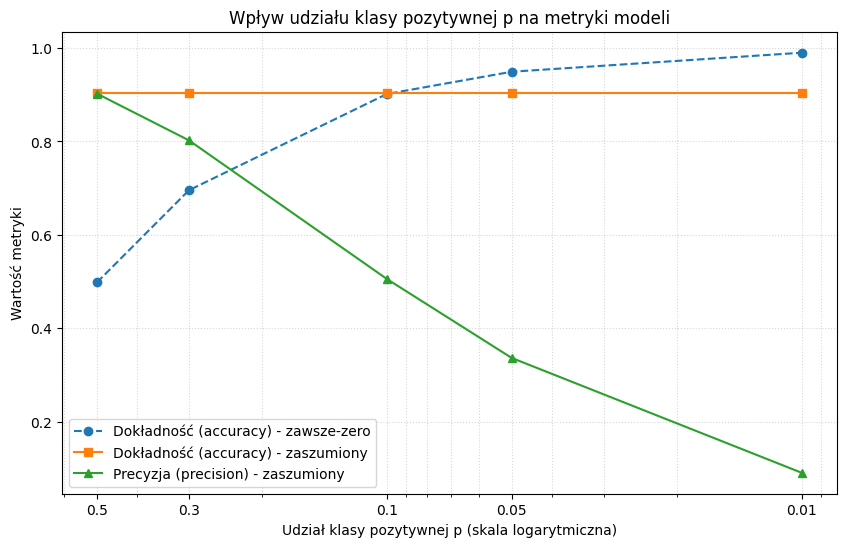

In [25]:
import matplotlib.pyplot as plt
# Twoje rozwiązanie (wykres)

df_zero = df[df["model"] == "zawsze-zero"]
df_noisy = df[df["model"] == "zaszumiony"]
plt.figure(figsize=(10, 6))
plt.plot(df_zero["p"], df_zero["accuracy"], marker='o', label="Dokładność (accuracy) - zawsze-zero", linestyle='--')
plt.plot(df_noisy["p"], df_noisy["accuracy"], marker='s', label="Dokładność (accuracy) - zaszumiony")
plt.plot(df_noisy["p"], df_noisy["precision"], marker='^', label="Precyzja (precision) - zaszumiony")
plt.xscale('log')
ps = [0.5, 0.3, 0.1, 0.05, 0.01]
plt.xticks(ps, labels=[str(p) for p in ps])
plt.gca().invert_xaxis()
plt.title("Wpływ udziału klasy pozytywnej p na metryki modeli")
plt.xlabel("Udział klasy pozytywnej p (skala logarytmiczna)")
plt.ylabel("Wartość metryki")
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend()
plt.show()

In [26]:
# TEST
assert set(df.columns) >= {"p", "model", "accuracy", "precision", "recall", "f1"}
assert len(df) == 10
z = df[(df["model"] == "zawsze-zero") & (df["p"] == 0.01)].iloc[0]
assert z["accuracy"] > 0.98 and z["recall"] == 0.0
print("D2 OK")

D2 OK


### Zadanie D3. Wnioski
Odpowiedz krótko (2–3 zdania na pytanie), odwołując się do liczb z tabeli:

1. Czy Twoje przewidywania z D1 się potwierdziły? Co Cię zaskoczyło?
2. Dla $p = 0.01$: który model ma wyższą accuracy, a który jest bardziej użyteczny? Dlaczego?
3. Model zaszumiony myli się zawsze w 10% przypadków. Dlaczego mimo to jego precision spada, gdy $p$ maleje?
4. Projektujesz system wykrywający rzadką chorobę. Którą metrykę zaraportujesz jako główną? Jakie konsekwencje dla pacjentów mają błędy FP, a jakie FN?

1. Przewidywania z D1 potwierdziły się. Model zawsze-zero uzyskał dla p=0.05 dokładność na poziomie 94.92% (zgodnie z przewidywanym 95%), podczas gdy model zaszumiony osiągnął 90.36% (zakładane 90%). Zgodnie z oczekiwaniami, precyzja modelu zaszumionego wyniosła 33.67%, co leży blisko wartości 0.3. Zaskakujące może być to, jak gwałtownie precyzja spada przy dalszym zmniejszaniu $p$ (dla p = 0.01 wynosi już tylko ok. 9.1%, mimo że model myli się tylko w 10% przypadków)

2. Dla p = 0.01 wyższą dokładność ma model zawsze-zero (98.99% vs 90.36%, czyli o prawie 9 pp więcej). Jednak znacznie bardziej użyteczny jest model zaszumiony, ponieważ ma bardzo wysoką czułość (95.05%) i potrafi wykryć niemal wszystkie rzeczywiste przypadki klasy pozytywnej. Model zawsze-zero ma czułość równą 0 - nie wykrywa żadnego zdarzenia, przez co jest całkowicie bezużyteczny.

3. Wynika to ze wzoru na precyzję: precision = TP / (TP + FP). Gdy p maleje, w danych pojawia się ogromna przewaga zer. Ponieważ model losowo psuje 10% odpowiedzi, generuje on bardzo dużo błędów fałszywie dodatnich FP z tej licznej grupy zer. Ta lawinowo rosnąca liczba fałszywych alarmów FP przy małej liczbie rzeczywistych jedynek TP powoduje drastyczny spadek wartości precyzji.

4. Jako główną metrykę wybrałbym recall, ponieważ w przypadku rzadkiej i groźnej choroby istotne jest wykrycie jak największej liczby rzeczywistych chorych i zminimalizowanie przeoczeń. FP może wiązać się się ze stresem i ewentualnymi kosztami u pacjenta, choć można go zweryfikować dodatkowymi badaniami, natomiast FN wiąże się z bezpośrednim zagrożeniem zdrowia i życia pacjenta ze względu na brak leczenia (na czas).

---
## Część E. Zadania dodatkowe (dla chętnych / do domu)

**E1. Pliki.** Zapisz listę wyników (po jednym w linii) do pliku `scores.txt`. Wczytaj plik, oblicz średnią i zapisz do `report.txt` raport w formacie `Wczytano N wyników, średnia: X` (X z dokładnością do 3 miejsc po przecinku).

**E2. Dane od użytkownika.** Pobierz funkcją `input()` wynik modelu `s` i wypisz:
- `Podano niepoprawną wartość!`, gdy tekstu nie da się zamienić na liczbę (`try`/`except`),
- `Wynik poza zakresem 0–1`, gdy `s < 0` lub `s > 1`,
- `Model wymaga poprawy`, gdy `s < 0.7`,
- `Wynik akceptowalny`, gdy `0.7 ≤ s < 0.85`,
- `Wynik doskonały` w pozostałych przypadkach.

**E3. Duplikaty.** Usuń duplikaty z listy `["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]` **z zachowaniem kolejności** pierwszych wystąpień. Dlaczego samo `list(set(...))` tego nie gwarantuje?

**E4. Uogólnienie.** Rozszerz `make_data` o parametr pozwalający ustawić osobno odsetek błędów dla przykładów pozytywnych i negatywnych. Jak zmienia się wykres z D2, gdy model myli się w 10% pozytywnych, ale tylko w 1% negatywnych?

Wczytano 5 wyników, średnia: 0.876
Podaj wynik modelu (0-1): 0.8
Wynik akceptowalny
['SVM', 'NeuralNet', 'Transformer']


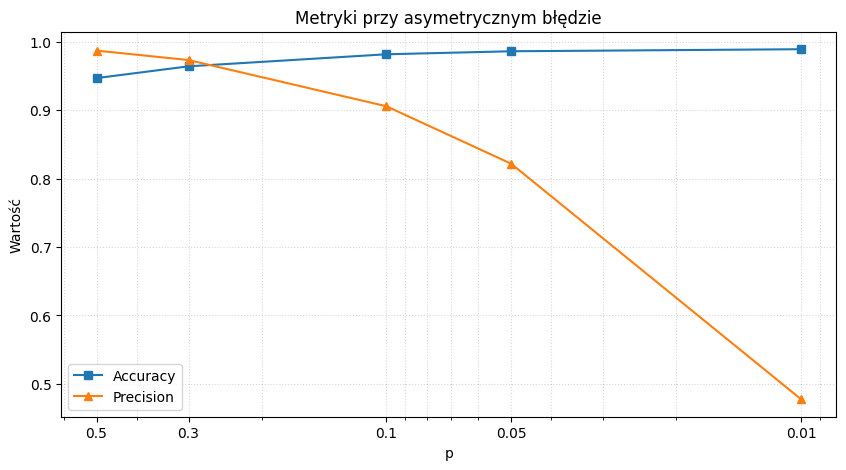

In [27]:
# E1
scores_list = [0.85, 0.92, 0.78, 0.95, 0.88]
with open('scores.txt', 'w') as f:
    for s in scores_list:
        f.write(f"{s}\n")

loaded_scores = []
with open('scores.txt', 'r') as f:
    for line in f:
        loaded_scores.append(float(line.strip()))

mean_score = sum(loaded_scores) / len(loaded_scores)
with open('report.txt', 'w') as f:
    f.write(f"Wczytano {len(loaded_scores)} wyników, średnia: {mean_score:.3f}")

print(f"Wczytano {len(loaded_scores)} wyników, średnia: {mean_score:.3f}")

# E2
user_input = input("Podaj wynik modelu (0-1): ")
try:
    s = float(user_input)
    if s < 0 or s > 1:
        print("Wynik poza zakresem 0–1")
    elif s < 0.7:
        print("Model wymaga poprawy")
    elif s < 0.85:
        print("Wynik akceptowalny")
    else:
        print("Wynik doskonały")
except ValueError:
    print("Podano niepoprawną wartość!")

# E3
models = ["SVM", "SVM", "NeuralNet", "NeuralNet", "Transformer"]
unique_models = list(dict.fromkeys(models))
print(unique_models)

# E4
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

def make_data_generalized(p, n=10_000, error_rate_pos=0.10, error_rate_neg=0.01, seed=42):
    rng = np.random.default_rng(seed)
    y_true = (rng.random(n) < p).astype(int)
    y_zero = np.zeros(n, dtype=int)
    flip_pos = rng.random(n) < error_rate_pos
    flip_neg = rng.random(n) < error_rate_neg
    y_noisy = np.copy(y_true)
    y_noisy[(y_true == 1) & flip_pos] = 0
    y_noisy[(y_true == 0) & flip_neg] = 1
    return y_true, y_zero, y_noisy

ps = [0.5, 0.3, 0.1, 0.05, 0.01]
rows_e4 = []
for p in ps:
    y_true, y_zero, y_noisy = make_data_generalized(p=p, error_rate_pos=0.10, error_rate_neg=0.01)
    m_noisy = binary_metrics(y_true, y_noisy)
    rows_e4.append({
        "p": p,
        "accuracy": m_noisy["accuracy"],
        "precision": m_noisy["precision"]
    })

df_e4 = pd.DataFrame(rows_e4)

plt.figure(figsize=(10, 5))
plt.plot(df_e4["p"], df_e4["accuracy"], marker='s', label="Accuracy")
plt.plot(df_e4["p"], df_e4["precision"], marker='^', label="Precision")
plt.xscale('log')
plt.xticks(ps, labels=[str(p) for p in ps])
plt.gca().invert_xaxis()
plt.title("Metryki przy asymetrycznym błędzie")
plt.xlabel("p")
plt.ylabel("Wartość")
plt.grid(True, which="both", linestyle=':', alpha=0.5)
plt.legend()
plt.show()

Odp do E3:  Zbiór w Pythonie jest oparty na tablicy mieszającej - pozycja elementów zależy od hashów - nie gwaranuje zachowania pierwotnej kolejności.
Odp do E4:  Dzięki ograniczeniu fałszywych alarmów FP do 1%, precyzja przy rzadkich klasach (np. p=0.01) rośnie z 9% aż do 48%, a dokładność modelu zaszumionego rośnie powyżej 98%